In [ ]:
import torch

print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    print("GPU Not Available")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected Device:", device)


PyTorch Version: 2.14.1+cpu
GPU Not Available
Selected Device: cpu


In [ ]:
!pip install -q torch torchvision numpy pandas matplotlib seaborn scikit-learn pillow tqdm

In [ ]:

# Import required libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, datasets, models

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:
!pip install -q datasets

In [ ]:
from datasets import load_dataset

ds = load_dataset("zacharielegault/Kermany2017-OCT")

print(ds)

README.md:   0%|          | 0.00/2.79k [00:00<?, ?B/s]

data/train-00000-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  369MB            

data/train-00000-of-00016.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  473MB            

data/train-00001-of-00016.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  462MB            

... (28 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/108309 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 108309
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1000
    })
})


In [ ]:
print(ds.keys())

dict_keys(['train', 'test'])


In [ ]:
train_data = ds["train"]
test_data = ds["test"]

print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

print(train_data.features)

Training samples: 108309
Testing samples: 1000
{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['CNV', 'DME', 'DRUSEN', 'NORMAL'])}


check distribution

In [ ]:
train_labels = train_data["label"]
test_labels = test_data["label"]

train_counts = pd.Series(train_labels).value_counts().sort_index()
test_counts = pd.Series(test_labels).value_counts().sort_index()

class_names = train_data.features["label"].names

distribution = pd.DataFrame({
    "Disease": class_names,
    "Training Images": train_counts.values,
    "Testing Images": test_counts.values
})

print(distribution)

  Disease  Training Images  Testing Images
0     CNV            37205             250
1     DME            11348             250
2  DRUSEN             8616             250
3  NORMAL            51140             250


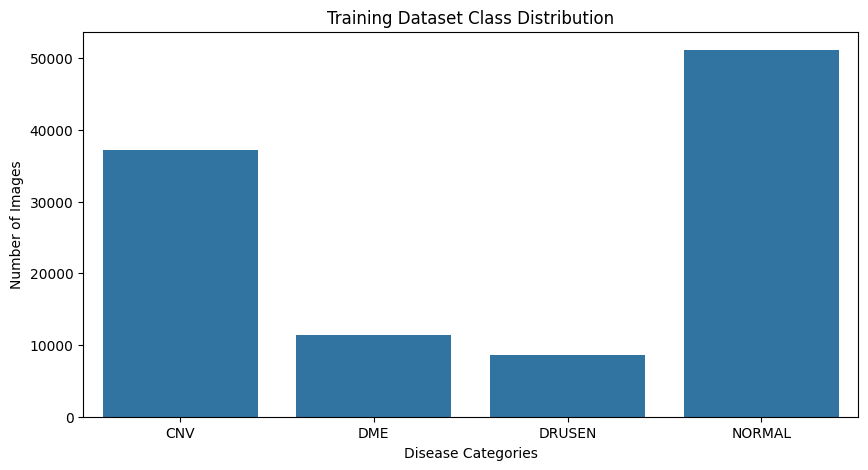

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=distribution,
    x="Disease",
    y="Training Images"
)

plt.title("Training Dataset Class Distribution")
plt.xlabel("Disease Categories")
plt.ylabel("Number of Images")
plt.show()

inspect the actual images

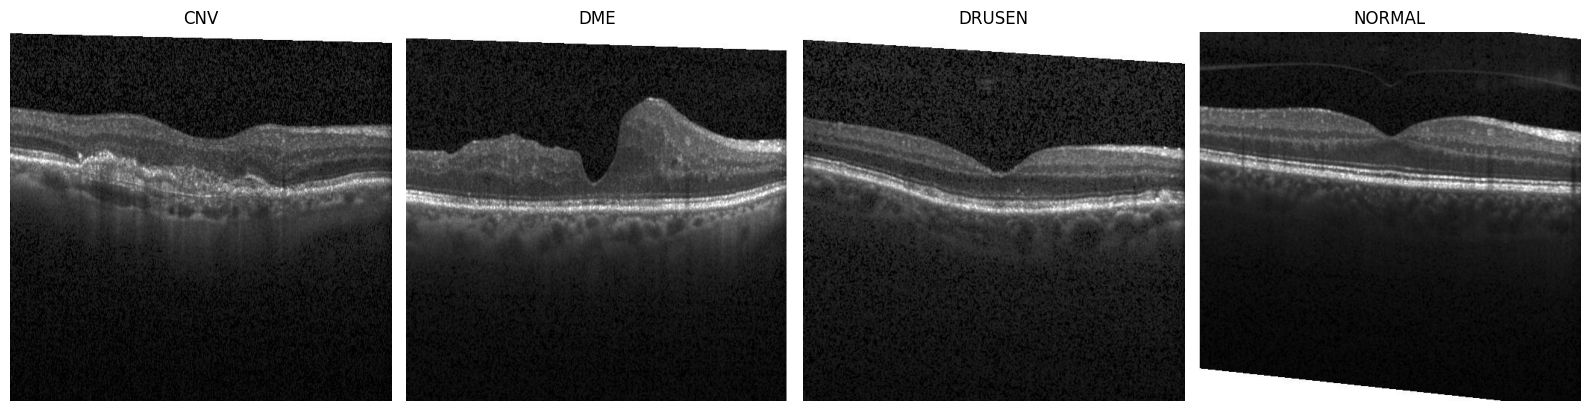

In [ ]:
class_names = train_data.features["label"].names

sample_indices = {}

for class_id, class_name in enumerate(class_names):
    index = next(
        i for i, label in enumerate(train_data["label"])
        if label == class_id
    )
    sample_indices[class_name] = index

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, (class_name, index) in zip(axes, sample_indices.items()):
    image = train_data[index]["image"]

    ax.imshow(image, cmap="gray")
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
sample_image = train_data[0]["image"]

image_array = np.array(sample_image)

print("Image Size:", sample_image.size)
print("Image Mode:", sample_image.mode)
print("Image Format:", sample_image.format)
print("Array Shape:", image_array.shape)
print("Data Type:", image_array.dtype)
print("Minimum Pixel Value:", image_array.min())
print("Maximum Pixel Value:", image_array.max())

Image Size: (512, 496)
Image Mode: L
Image Format: JPEG
Array Shape: (496, 512)
Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255


In [ ]:
image_sizes = []

for i in range(100):
    image = train_data[i]["image"]
    image_sizes.append(image.size)

size_counts = pd.Series(image_sizes).value_counts()

print("Unique Image Dimensions:", len(size_counts))
print(size_counts.head(15))

Unique Image Dimensions: 3
(512, 496)     45
(768, 496)     31
(1536, 496)    24
Name: count, dtype: int64


Transform the images to tensor and size of 224 x 224

In [ ]:
from torchvision import transforms

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor()
])

sample = train_data[0]["image"]

processed_image = preprocess(sample)

print("Original Image Size:", sample.size)
print("Processed Tensor Shape:", processed_image.shape)
print("Tensor Data Type:", processed_image.dtype)
print("Minimum Value:", processed_image.min().item())
print("Maximum Value:", processed_image.max().item())

Original Image Size: (512, 496)
Processed Tensor Shape: torch.Size([3, 224, 224])
Tensor Data Type: torch.float32
Minimum Value: 0.003921568859368563
Maximum Value: 1.0


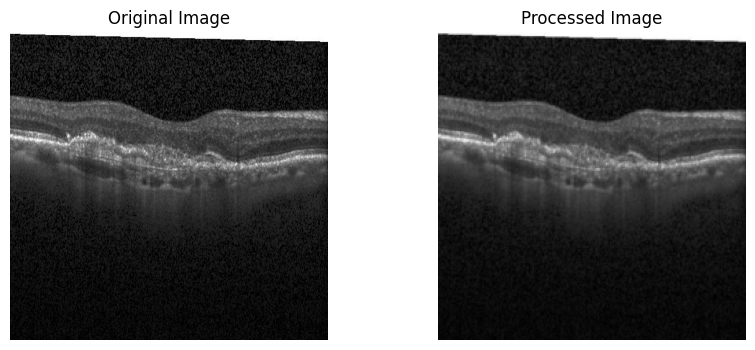

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed_image.permute(1, 2, 0))
plt.title("Processed Image")
plt.axis("off")

plt.show()

In [ ]:
channel_sum = torch.zeros(3)
channel_squared_sum = torch.zeros(3)
total_pixels = 0

for i in range(1000):
    image = preprocess(train_data[i]["image"])

    channel_sum += image.sum(dim=(1, 2))
    channel_squared_sum += (image ** 2).sum(dim=(1, 2))

    total_pixels += image.shape[1] * image.shape[2]

dataset_mean = channel_sum / total_pixels

dataset_std = torch.sqrt(
    channel_squared_sum / total_pixels - dataset_mean ** 2
)

print("Dataset Mean:", dataset_mean)
print("Dataset Standard Deviation:", dataset_std)

Dataset Mean: tensor([0.2022, 0.2022, 0.2022])
Dataset Standard Deviation: tensor([0.2133, 0.2133, 0.2133])


Data Augmentation

Training pipeline: Includes augmentation.



Testing pipeline: Only preprocessing and normalization.

Training

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(degrees=5),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.2022, 0.2022, 0.2022],
        std=[0.2133, 0.2133, 0.2133]
    )
])

Testing

In [ ]:
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.2022, 0.2022, 0.2022],
        std=[0.2133, 0.2133, 0.2133]
    )
])

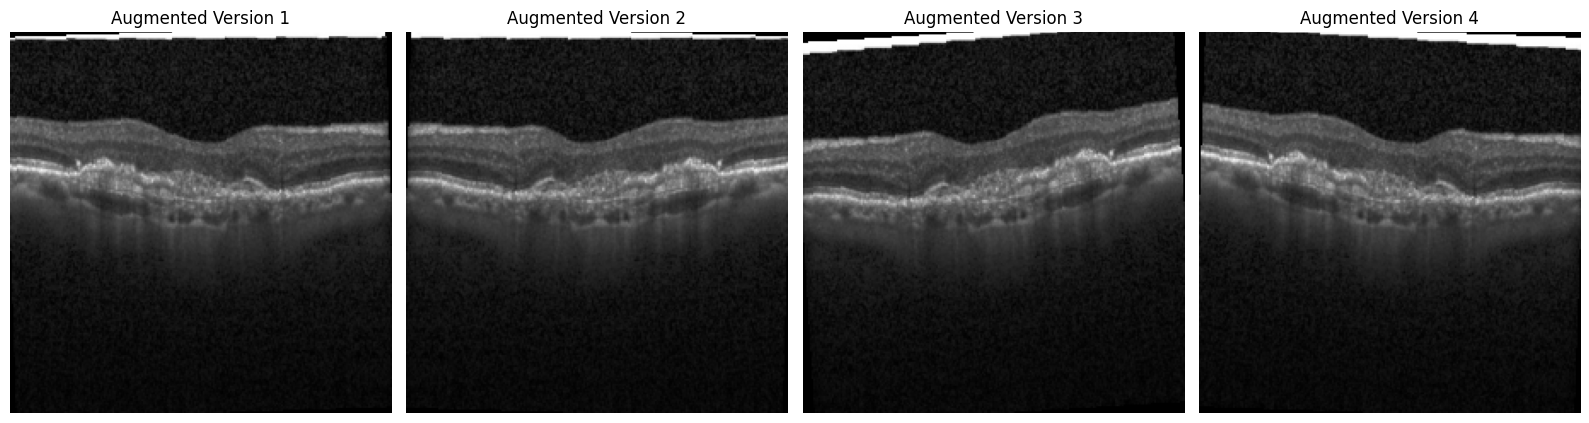

In [ ]:
sample_image = train_data[0]["image"]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for i, ax in enumerate(axes):
    augmented_image = train_transform(sample_image)

    display_image = augmented_image[:3].permute(1, 2, 0)

    display_image = (
        display_image * 0.2133 + 0.2022
    ).clamp(0, 1)

    ax.imshow(display_image)
    ax.set_title(f"Augmented Version {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

create a validation dataset

In [ ]:
from sklearn.model_selection import train_test_split

all_indices = np.arange(len(train_data))

all_labels = np.array(train_data["label"])

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.10,
    random_state=42,
    stratify=all_labels
)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Testing samples:", len(test_data))

Training samples: 97478
Validation samples: 10831
Testing samples: 1000


PyTorch Dataset

In [ ]:
class OCTDataset(Dataset):

    def __init__(self, dataset, indices=None, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        if self.indices is not None:
            return len(self.indices)

        return len(self.dataset)

    def __getitem__(self, index):

        if self.indices is not None:
            index = int(self.indices[index])

        sample = self.dataset[index]

        image = sample["image"]
        label = sample["label"]

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

In [ ]:
train_dataset = OCTDataset(
    train_data,
    indices=train_indices,
    transform=train_transform
)

val_dataset = OCTDataset(
    train_data,
    indices=val_indices,
    transform=test_transform
)

test_dataset = OCTDataset(
    test_data,
    transform=test_transform
)

print("Training Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Testing Dataset:", len(test_dataset))

Training Dataset: 97478
Validation Dataset: 10831
Testing Dataset: 1000


DataLoaders

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
images, labels = next(iter(train_loader))

print("Image Batch Shape:", images.shape)
print("Label Batch Shape:", labels.shape)
print("Image Data Type:", images.dtype)
print("Label Data Type:", labels.dtype)
print("GPU Available:", torch.cuda.is_available())

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Image Batch Shape: torch.Size([32, 3, 224, 224])
Label Batch Shape: torch.Size([32])
Image Data Type: torch.float32
Label Data Type: torch.int64
GPU Available: False


###CNN

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

CNN WITH MAXPOOLING

In [ ]:
class CustomCNN1(nn.Module):

    def __init__(self):
        super(CustomCNN1, self).__init__()

        self.conv_block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.conv_block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 4)
        )

    def forward(self, x):

        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)

        x = self.global_pool(x)

        x = self.classifier(x)

        return x

In [ ]:
model1 = CustomCNN1().to(device)

sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images.to(device)

model1.eval()

with torch.no_grad():
    output = model1(sample_images)

print("Input Shape:", sample_images.shape)
print("Output Shape:", output.shape)
print("Model Parameters:", sum(p.numel() for p in model1.parameters()))

Input Shape: torch.Size([32, 3, 224, 224])
Output Shape: torch.Size([32, 4])
Model Parameters: 110724


class weights

In [ ]:
class_counts = np.bincount(
    all_labels[train_indices],
    minlength=4
)

class_weights = len(train_indices) / (4 * class_counts)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class Counts:", class_counts)
print("Class Weights:", class_weights)

Class Counts: [33485 10213  7754 46026]
Class Weights: tensor([0.7278, 2.3861, 3.1428, 0.5295])


In [ ]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

In [ ]:
optimizer = optim.Adam(
    model1.parameters(),
    lr=0.001
)

In [ ]:
from tqdm.auto import tqdm
import torch.nn.functional as F

def train_one_epoch(model, loader, criterion, optimizer, device, class_weights):

    model.train()

    loss_sum = 0
    weight_sum = 0
    correct = 0
    total = 0

    for images, labels in tqdm(loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        individual_losses = F.cross_entropy(
            outputs,
            labels,
            weight=class_weights,
            reduction="none"
        )

        loss_sum += individual_losses.sum().item()
        weight_sum += class_weights[labels].sum().item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = loss_sum / weight_sum
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
def validate_one_epoch(model, loader, criterion, device, class_weights):

    model.eval()

    loss_sum = 0
    weight_sum = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in tqdm(loader):

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            individual_losses = F.cross_entropy(
                outputs,
                labels,
                weight=class_weights,
                reduction="none"
            )

            loss_sum += individual_losses.sum().item()
            weight_sum += class_weights[labels].sum().item()

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = loss_sum / weight_sum
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
num_epochs = 5

best_val_accuracy = 0

history1 = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):

    print(f"\nEpoch {epoch+1}/{num_epochs}")

    train_loss, train_acc = train_one_epoch(
        model1,
        train_loader,
        criterion,
        optimizer,
        device,
        class_weights
    )

    val_loss, val_acc = validate_one_epoch(
        model1,
        val_loader,
        criterion,
        device,
        class_weights
    )

    history1["train_loss"].append(train_loss)
    history1["val_loss"].append(val_loss)

    history1["train_accuracy"].append(train_acc)
    history1["val_accuracy"].append(val_acc)

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")

    print(f"Training Accuracy: {train_acc:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")

    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc

        torch.save(
            model1.state_dict(),
            "custom_cnn1_best.pth"
        )

        print("Best model saved!")

print("\nBest Validation Accuracy:", best_val_accuracy)


Epoch 1/5


  0%|          | 0/3047 [00:00<?, ?it/s]

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [ ]:
import random

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [ ]:
model1 = CustomCNN1().to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = optim.Adam(
    model1.parameters(),
    lr=0.001
)

num_epochs = 5

best_val_accuracy = 0

history1_retrained = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

print("CNN 1 reinitialized successfully!")

In [ ]:
for epoch in range(num_epochs):

    print(f"\nEpoch {epoch+1}/{num_epochs}")

    train_loss, train_acc = train_one_epoch(
        model1,
        train_loader,
        criterion,
        optimizer,
        device,
        class_weights
    )

    val_loss, val_acc = validate_one_epoch(
        model1,
        val_loader,
        criterion,
        device,
        class_weights
    )

    history1_retrained["train_loss"].append(train_loss)
    history1_retrained["val_loss"].append(val_loss)

    history1_retrained["train_accuracy"].append(train_acc)
    history1_retrained["val_accuracy"].append(val_acc)

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")

    print(f"Training Accuracy: {train_acc:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")

    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc

        torch.save(
            model1.state_dict(),
            "custom_cnn1_retrained_best.pth"
        )

        print("Best retrained model saved!")

print("\nBest Validation Accuracy:", best_val_accuracy)

CNN 2 – Without MaxPooling

In [ ]:
class CustomCNN2(nn.Module):

    def __init__(self):
        super(CustomCNN2, self).__init__()

        self.conv_block1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU()
        )

        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )

        self.conv_block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 4)
        )

    def forward(self, x):

        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)

        x = self.global_pool(x)

        x = self.classifier(x)

        return x

In [ ]:
model2 = CustomCNN2().to(device)

sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images.to(device)

model2.eval()

with torch.no_grad():
    output = model2(sample_images)

print("Input Shape:", sample_images.shape)
print("Output Shape:", output.shape)

print(
    "Model Parameters:",
    sum(p.numel() for p in model2.parameters())
)

In [ ]:
criterion2 = nn.CrossEntropyLoss(weight=class_weights)

optimizer2 = optim.Adam(model2.parameters(), lr=0.001)

best_val_acc2 = 0

for epoch in range(5):
    train_loss, train_acc = train_one_epoch(
        model2, train_loader, criterion2, optimizer2, device, class_weights
    )

    val_loss, val_acc = validate_one_epoch(
        model2, val_loader, criterion2, device, class_weights
    )

    print(f"Epoch {epoch+1}/5")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f}")

    if val_acc > best_val_acc2:
        best_val_acc2 = val_acc
        torch.save(model2.state_dict(), "custom_cnn2_best.pth")

print("Best Validation Accuracy:", best_val_acc2)